In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
model_path = "/content/drive/MyDrive/objectification_model.h5"


In [ ]:
from tensorflow.keras.models import load_model

model = load_model(model_path)
print("Model loaded successfully!")


Model loaded successfully!


In [ ]:
import numpy as np

In [ ]:
import cv2
import os

def extract_frames_from_video(video_path, target_size=(224, 224), max_frames=30):
    import cv2
    frames = []
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frame_interval = max(total_frames // max_frames, 1)

    count = 0
    while cap.isOpened() and len(frames) < max_frames:
        ret, frame = cap.read()
        if not ret:
            break
        if count % frame_interval == 0:
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame_resized = cv2.resize(frame_rgb, target_size)
            frame_normalized = frame_resized / 255.0
            frames.append((frame_normalized, frame_rgb))  # (model input, original)
        count += 1
    cap.release()
    return frames




In [ ]:
def is_blurry(frame_rgb, threshold=100.0):
    gray = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2GRAY)
    lap_var = cv2.Laplacian(gray, cv2.CV_64F).var()
    return lap_var < threshold


In [ ]:
!pip install transformers accelerate opencv-python-headless --quiet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 72.8 MB/s eta 0:00:00


In [ ]:
# Load BLIP image captioning model from Hugging Face
from transformers import BlipProcessor, BlipForConditionalGeneration
import torch
from PIL import Image
import requests

# Load BLIP captioning model and processor
processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
model_blip = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base").to("cuda" if torch.cuda.is_available() else "cpu")

def get_blip_caption(image_np):
    """
    Generate a BLIP caption for a given RGB frame (numpy image)
    """
    pil_image = Image.fromarray(image_np)
    inputs = processor(images=pil_image, return_tensors="pt").to(model_blip.device)
    out = model_blip.generate(**inputs)
    caption = processor.decode(out[0], skip_special_tokens=True)
    return caption



Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/990M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

In [ ]:
objectification_keywords = [
    "scantily", "seductive", "sexual", "posing","lips", "revealing",
    "bikini", "underwear", "shorts", "cleavage", "legs",
    "dressed", "body", "lingerie", "skin", "modeling", "exposing"
]


In [ ]:
def predict_objectification(frames, model, top_n=5):
    model_inputs = np.array([f[0] for f in frames])
    preds = model.predict(model_inputs, verbose=0).flatten()

    avg_score = np.mean(preds)
    print(f"📊 Objectification Score: {avg_score * 100:.2f}%")

    if avg_score < 0.5:
        print("🚫 This video is not objectified.")
        return

    # Get top scored frames
    top_indices = preds.argsort()[::-1]

    objectification_keywords = [
        "scantily", "seductive", "sexual", "posing", "revealing",
        "bikini", "underwear", "shorts", "cleavage", "legs",
        "dressed", "body", "lingerie", "skin", "modeling", "exposing"
    ]

    # Filter top-N frames using captions
    filtered = []
    for idx in top_indices:
        frame_rgb = frames[idx][1]
        caption = get_blip_caption(frame_rgb)

        if any(keyword in caption.lower() for keyword in objectification_keywords):
            filtered.append((idx, caption))
        if len(filtered) == top_n:
            break

    if not filtered:
        print("🚫 No objectifying frames (with sexualized captions) found.")
        return

    print(f"🖼️ Showing Top {len(filtered)} Objectifying Frames Based on Captions...\n")

    plt.figure(figsize=(15, 5))
    for i, (idx, caption) in enumerate(filtered):
        plt.subplot(1, len(filtered), i + 1)
        plt.imshow(frames[idx][1])
        plt.title(f"Frame {idx + 1}\n{caption}", fontsize=10)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


Saving Stereotypes in Commercials_ Fast Food.mp4 to Stereotypes in Commercials_ Fast Food (8).mp4
📊 Objectification Score: 51.15%
🖼️ Showing Top 2 Objectifying Frames Based on Captions...



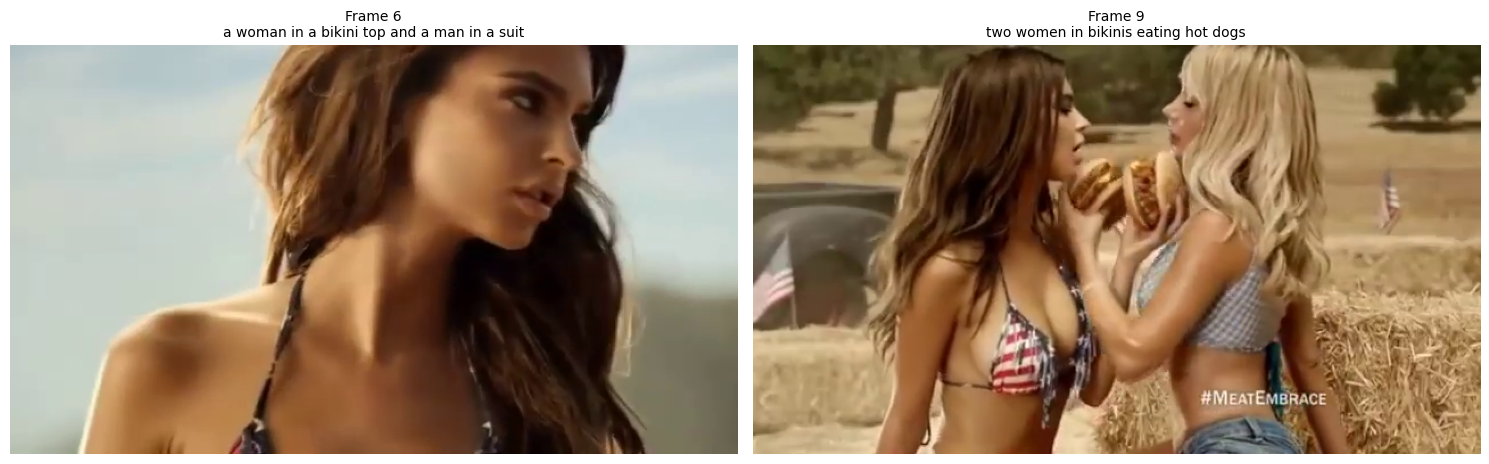

In [ ]:
from google.colab import files
uploaded = files.upload()

video_path = list(uploaded.keys())[0]
frames = extract_frames_from_video(video_path, target_size=(224, 224), max_frames=30)
predict_objectification(frames, model, top_n=5)


In [ ]:
from google.colab import files
uploaded = files.upload()

# Get uploaded video path
video_path = list(uploaded.keys())[0]
frames = extract_frames_from_video(video_path, target_size=(224, 224), max_frames=30)
predict_objectification(frames, model, top_n=5)


Saving Nike Women's Ad - SNL.mp4 to Nike Women's Ad - SNL (1).mp4
📊 Objectification Score: 33.42%
🚫 This video is not objectified.


Saving Kendall Jenner in Calvins or nothing _ Calvin Klein Spring 2023.mp4 to Kendall Jenner in Calvins or nothing _ Calvin Klein Spring 2023 (1).mp4
📊 Objectification Score: 61.08%
🖼️ Showing Top 5 Objectifying Frames Based on Captions...



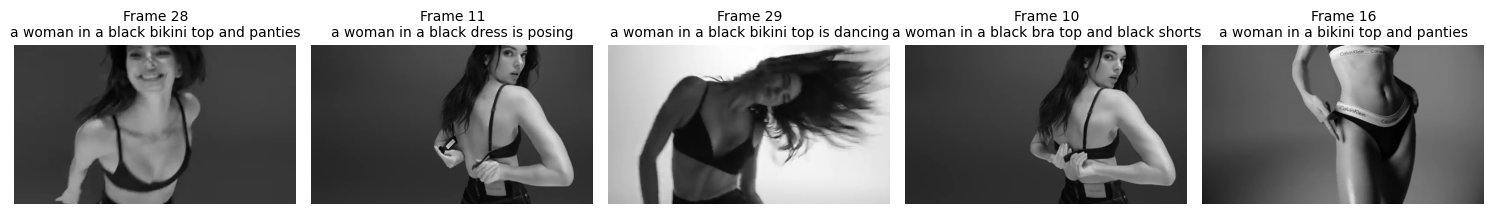

In [ ]:
from google.colab import files
uploaded = files.upload()

# Get uploaded video path
video_path = list(uploaded.keys())[0]
frames = extract_frames_from_video(video_path, target_size=(224, 224), max_frames=30)
predict_objectification(frames, model, top_n=5)


In [ ]:
from google.colab import files
uploaded = files.upload()

# Get uploaded video path
video_path = list(uploaded.keys())[0]
frames = extract_frames_from_video(video_path, target_size=(224, 224), max_frames=30)
predict_objectification(frames, model, top_n=5)

Saving videoplayback (1).mp4 to videoplayback (1) (1).mp4
📊 Objectification Score: 48.22%
🚫 This video is not objectified.


In [ ]:
from google.colab import files
uploaded = files.upload()

# Get uploaded video path
video_path = list(uploaded.keys())[0]
frames = extract_frames_from_video(video_path, target_size=(224, 224), max_frames=30)
predict_objectification(frames, model, top_n=5)

Saving Women Who Empower - Teaser.mp4 to Women Who Empower - Teaser (1).mp4
📊 Objectification Score: 42.41%
🚫 This video is not objectified.


In [ ]:
from google.colab import files
uploaded = files.upload()

# Get uploaded video path
video_path = list(uploaded.keys())[0]
frames = extract_frames_from_video(video_path, target_size=(224, 224), max_frames=30)
predict_objectification(frames, model, top_n=5)

Saving Tropicana Slice ft  Katrina Kaif.mp4 to Tropicana Slice ft  Katrina Kaif.mp4
📊 Objectification Score: 22.26%
🚫 This video is not objectified.


In [ ]:
from google.colab import files
uploaded = files.upload()

# Get uploaded video path
video_path = list(uploaded.keys())[0]
frames = extract_frames_from_video(video_path, target_size=(224, 224), max_frames=30)
predict_objectification(frames, model, top_n=5)

Saving Tropicana Slice ft  Katrina Kaif.mp4 to Tropicana Slice ft  Katrina Kaif.mp4
📊 Objectification Score: 22.26%
🚫 This video is not objectified.


In [ ]:
import matplotlib.pyplot as plt


Saving Mango Slice Ad Campaign   TVC With Katrina Kaif.mp4 to Mango Slice Ad Campaign   TVC With Katrina Kaif (1).mp4
📊 Objectification Score: 75.90%
🖼️ Showing Top 1 Objectifying Frames Based on Captions...



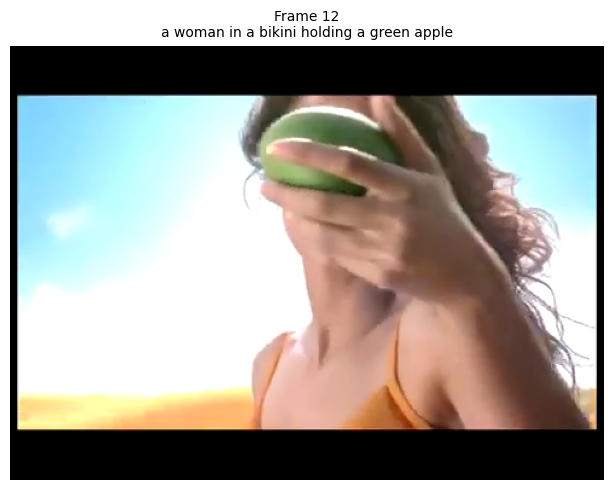

In [ ]:
from google.colab import files
uploaded = files.upload()

# Get uploaded video path
video_path = list(uploaded.keys())[0]
frames = extract_frames_from_video(video_path, target_size=(224, 224), max_frames=30)
predict_objectification(frames, model, top_n=5)